# Notebook 3: baseline BLIP-2 video explanation (ExDDV, FaceForensics++)

Fine-tunes `Salesforce/blip2-flan-t5-xl` to explain why a fake video is fake. Each video is 5 face crops (notebook 1). Every crop goes through the frozen ViT and then the Q-Former separately (32 query tokens each); the 5x32 visual tokens, plus a learned frame-position embedding, are concatenated with the prompt embeddings and fed to the Flan-T5 encoder.

**Needs:** dataset `kishlaytejeswi/vlm-nlp` is NOT needed here. Attach notebook 1's output dataset (`metadata.csv` + `crops/`). GPU T4 (only GPU 0 is used), internet on. Notebook 2 is not required.

**Pipeline:** (1) cache frozen-ViT features in fp16 to `/tmp` (about 11 GB, a few minutes), (2) train from the cache with Q-Former + LoRA + projection + query tokens + frame embeddings trainable, (3) evaluate the best checkpoint on test.

**Controls included so the result can be read honestly:** a constant-sentence baseline, and the same model fed *shuffled* videos (features of a different test video). If shuffled scores are about the same as real scores, the model is writing a generic caption and is not using the video.

**Known data issue:** the official split shares source IDs between train and test (notebook 1 found 256 of 271 test videos share the first ID with a train video). The split is kept as is for comparability; the metrics are also reported on the small subset with an unseen ID.

**Outputs** (`/kaggle/working/blip2_baseline/`): `best.pt`, `last.pt`, `history.csv`, `test_predictions.csv`, `results.csv`, `results.json`.

If a model load fails, restart the session instead of re-running the cell.

In [1]:
import os, sys
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["HF_HOME"] = "/tmp/hf"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [2]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade transformers peft accelerate sentence-transformers rouge-score "pillow<13.0"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
litellm 1.109.1 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 2.4.0 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


In [3]:
sys.modules["bitsandbytes"] = None
import gc, json, math, time, random, shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import peft, peft.import_utils as piu
for _n in dir(piu):
    _f = getattr(piu, _n)
    if _n.startswith("is_") and hasattr(_f, "cache_clear"): _f.cache_clear()
import transformers
from transformers import Blip2ForConditionalGeneration, AutoTokenizer, BlipImageProcessor
from peft import LoraConfig, inject_adapter_in_model
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__)
assert torch.cuda.is_available(), "turn on a GPU (T4) in the notebook settings"
DEV = torch.device("cuda:0")
print(torch.cuda.get_device_name(0), "| free GB:", round(torch.cuda.mem_get_info()[0] / 1e9, 1))

torch 2.11.0+cu130 | transformers 5.24.1 | peft 0.22.0
Tesla T4 | free GB: 15.5


In [4]:
MODEL = "Salesforce/blip2-flan-t5-xl"
PROMPT = "What is wrong in the images? Explain why they look real or fake."
N_FRAMES = 5
EPOCHS, MICRO_BS, ACCUM = 10, 2, 4
LR_LORA, LR_QF, LR_FRAME = 2e-4, 5e-5, 1e-3
WD, WARMUP_FRAC, CLIP = 0.01, 0.05, 1.0
LORA_R, LORA_ALPHA = 16, 32
TRAIN_QFORMER = True
MAX_LEN = 96
VIT_BATCH = 8
GEN = dict(num_beams=5, max_new_tokens=64, min_new_tokens=3, no_repeat_ngram_size=3)
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

OUT_DIR = Path("/kaggle/working/blip2_baseline"); OUT_DIR.mkdir(parents=True, exist_ok=True)
FEAT_PATH = Path("/tmp/feats_fp16.npy"); FEAT_DONE = Path("/tmp/feats_fp16.done")

## 1. Load notebook 1's output

In [5]:
cands = [p for p in Path("/kaggle/input/datasets/kishlaytejeswi/vlm-nlp/notebook1").rglob("metadata.csv") if (p.parent / "crops").is_dir()]
assert cands, "no metadata.csv with a sibling crops/ folder under /kaggle/input"
PREP = cands[0].parent; print("prep dir:", PREP)
meta = pd.read_csv(PREP / "metadata.csv")
meta["crop_paths"] = meta.crop_paths.map(json.loads)
meta["text"] = meta.text.fillna("").astype(str).str.strip()
meta["stem"] = meta.key.str.split("/").str[1]
meta["id_a"] = meta.stem.str.extract(r"^(\d+)")[0]
meta["id_in_train"] = meta.id_a.isin(set(meta.loc[meta.split == "train", "id_a"]))
missing = sum(not (PREP / p).exists() for ps in meta.crop_paths for p in ps)
print(meta.shape, meta.split.value_counts().to_dict(), "| missing crop files:", missing, "| empty texts:", int((meta.text == "").sum()))
print("test videos with a first ID that also appears in train:", int(meta[meta.split == "test"].id_in_train.sum()), "/", int((meta.split == "test").sum()))
IDX = {s: np.where(meta.split.values == s)[0] for s in ["train", "val", "test"]}
N = len(meta)

prep dir: /kaggle/input/datasets/kishlaytejeswi/vlm-nlp/notebook1
(2993, 19) {'train': 2453, 'test': 271, 'val': 269} | missing crop files: 0 | empty texts: 0
test videos with a first ID that also appears in train: 256 / 271


In [6]:
tok = AutoTokenizer.from_pretrained(MODEL)
LAB = tok(list(meta.text), max_length=MAX_LEN, truncation=True).input_ids
full = tok(list(meta.text)).input_ids
ln = pd.Series([len(x) for x in full])
print("target tokens: mean %.1f, p95 %d, max %d | truncated at %d: %d" % (ln.mean(), ln.quantile(.95), ln.max(), MAX_LEN, (ln > MAX_LEN).sum()))

def make_labels(vids):
    L = max(len(LAB[v]) for v in vids)
    out = torch.full((len(vids), L), -100, dtype=torch.long)
    for i, v in enumerate(vids): out[i, :len(LAB[v])] = torch.tensor(LAB[v])
    return out.to(DEV)

target tokens: mean 20.4, p95 48, max 89 | truncated at 96: 0


## 2. Load BLIP-2 (fp16, GPU 0)

In [7]:
gc.collect(); torch.cuda.empty_cache()
proc = BlipImageProcessor.from_pretrained(MODEL)
model = Blip2ForConditionalGeneration.from_pretrained(MODEL, torch_dtype=torch.float16, device_map={"": 0})
print(type(model.language_model).__name__, "| GPU GB used:", round(torch.cuda.memory_allocated() / 1e9, 1))
print("qformer dtype:", next(model.qformer.parameters()).dtype, "| T5 dtype:", next(model.language_model.parameters()).dtype)

Loading weights:   0%|          | 0/1289 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie language_model.shared.weight to language_model.lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


T5ForConditionalGeneration | GPU GB used: 9.1
qformer dtype: torch.float32 | T5 dtype: torch.float16


## 3. Cache frozen-ViT features (fp16, resumable only within the same session)

In [8]:
vit = model.vision_model
V_TOK = (vit.config.image_size // vit.config.patch_size) ** 2 + 1
V_DIM = vit.config.hidden_size
need_gb = N * N_FRAMES * V_TOK * V_DIM * 2 / 1e9
print(f"cache shape ({N}, {N_FRAMES}, {V_TOK}, {V_DIM}) fp16 = {need_gb:.1f} GB | /tmp free GB: {shutil.disk_usage('/tmp').free / 1e9:.1f}")
assert shutil.disk_usage("/tmp").free / 1e9 > need_gb + 2, "not enough space in /tmp"

MEAN = torch.tensor(proc.image_mean, device=DEV).view(1, 3, 1, 1)
STD = torch.tensor(proc.image_std, device=DEV).view(1, 3, 1, 1)

def read_video(i):
    return np.stack([cv2.cvtColor(cv2.imread(str(PREP / p)), cv2.COLOR_BGR2RGB) for p in meta.crop_paths.iloc[i]])

if not (FEAT_PATH.exists() and FEAT_DONE.exists()):
    feats = np.lib.format.open_memmap(FEAT_PATH, mode="w+", dtype=np.float16, shape=(N, N_FRAMES, V_TOK, V_DIM))
    t0 = time.time()
    with ThreadPoolExecutor(4) as ex, torch.no_grad():
        for s in tqdm(range(0, N, VIT_BATCH)):
            ids = list(range(s, min(N, s + VIT_BATCH)))
            arr = np.stack(list(ex.map(read_video, ids)))
            x = torch.from_numpy(arr).to(DEV).permute(0, 1, 4, 2, 3).float().div_(255).flatten(0, 1)
            h = vit(pixel_values=((x - MEAN) / STD).half()).last_hidden_state
            feats[ids[0]:ids[-1] + 1] = h.view(len(ids), N_FRAMES, V_TOK, V_DIM).cpu().numpy()
    feats.flush(); del feats
    FEAT_DONE.write_text("ok")
    print(f"cached in {(time.time() - t0) / 60:.1f} min")
else:
    print("cache already present")

FE = np.load(FEAT_PATH, mmap_mode="r")
print(FE.shape, FE.dtype, "| sanity: finite =", bool(np.isfinite(FE[0].astype(np.float32)).all()), "| std of video 0: %.3f" % FE[0].astype(np.float32).std())

del vit; model.vision_model = None
gc.collect(); torch.cuda.empty_cache()
print("GPU GB used after dropping ViT:", round(torch.cuda.memory_allocated() / 1e9, 1))

cache shape (2993, 5, 257, 1408) fp16 = 10.8 GB | /tmp free GB: 2681.3


  0%|          | 0/375 [00:00<?, ?it/s]

cached in 31.5 min
(2993, 5, 257, 1408) float16 | sanity: finite = True | std of video 0: 0.826
GPU GB used after dropping ViT: 7.1


## 4. Trainable parts

LoRA (r=16, alpha=32, on T5 `q` and `v`, encoder and decoder), Q-Former, query tokens, language projection, frame embeddings. ViT and the T5 base weights stay frozen. T5 `wo` layers are kept in fp32, all trainable parameters are fp32, no autocast, dropout off (`model.eval()` throughout).

In [9]:
lm = model.language_model
assert hasattr(lm, "_shift_right") and hasattr(lm, "generate")
for p in model.parameters(): p.requires_grad = False
for n, m in lm.named_modules():
    if n.endswith(".wo"): m.float()

lm = inject_adapter_in_model(LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=0.0, target_modules=["q", "v"], bias="none"), lm)
lora_params = [p for n, p in lm.named_parameters() if "lora_" in n]
for p in lora_params: p.data = p.data.float(); p.requires_grad = True

model.qformer.float()
qf_params = list(model.qformer.parameters()) if TRAIN_QFORMER else []
for p in qf_params: p.requires_grad = True
model.query_tokens.data = model.query_tokens.data.float(); model.query_tokens.requires_grad = True
model.language_projection.float()
for p in model.language_projection.parameters(): p.requires_grad = True

D_T5 = lm.config.d_model
model.frame_emb = nn.Parameter(torch.randn(N_FRAMES, 1, D_T5, device=DEV) * 0.02)
NQ = model.query_tokens.shape[1]

head_params = [model.query_tokens] + list(model.language_projection.parameters())
groups = [{"params": lora_params, "lr": LR_LORA}, {"params": qf_params + head_params, "lr": LR_QF}, {"params": [model.frame_emb], "lr": LR_FRAME}]
trainable = [p for g in groups for p in g["params"]]
cnt = lambda ps: sum(p.numel() for p in ps) / 1e6
print(f"trainable M: LoRA {cnt(lora_params):.1f} | Q-Former {cnt(qf_params):.1f} | query+proj {cnt(head_params):.1f} | frame {cnt([model.frame_emb]):.3f}")
print("dtypes of trainables:", {str(p.dtype) for p in trainable}, "| wo dtype:", next(m for n, m in lm.named_modules() if n.endswith("encoder.block.0.layer.1.DenseReluDense.wo")).weight.dtype)
model.eval()

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


trainable M: LoRA 9.4 | Q-Former 105.1 | query+proj 1.6 | frame 0.010
dtypes of trainables: {'torch.float32'} | wo dtype: torch.float32


Blip2ForConditionalGeneration(
  (vision_model): None
  (qformer): Blip2QFormerModel(
    (layernorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
    (encoder): Blip2QFormerEncoder(
      (layer): ModuleList(
        (0): Blip2QFormerLayer(
          (attention): Blip2QFormerAttention(
            (attention): Blip2QFormerMultiHeadAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): Blip2QFormerSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
          )
          (crossattention): Blip2QFormerAttention(
            (attention): 

In [10]:
emb_layer = lm.get_input_embeddings(); EDT = emb_layer.weight.dtype
prompt_ids = tok(PROMPT, return_tensors="pt").input_ids.to(DEV)

def encode_video(feats):
    B, T = feats.shape[:2]
    q = model.query_tokens.expand(B * T, -1, -1)
    h = model.qformer(query_embeds=q, encoder_hidden_states=feats.flatten(0, 1).float()).last_hidden_state
    h = model.language_projection(h).view(B, T, NQ, -1) + model.frame_emb[None, :T]
    return h.flatten(1, 2)

def build_inputs(feats):
    vis = encode_video(feats)
    pe = emb_layer(prompt_ids).expand(vis.shape[0], -1, -1)
    emb = torch.cat([vis.to(EDT), pe], 1)
    return emb, torch.ones(emb.shape[:2], dtype=torch.long, device=DEV)

def seq_loss(feats, labels, reduction="mean"):
    emb, mask = build_inputs(feats)
    logits = lm(inputs_embeds=emb, attention_mask=mask, decoder_input_ids=lm._shift_right(labels)).logits.float()
    return F.cross_entropy(logits.view(-1, logits.size(-1)), labels.view(-1), ignore_index=-100, reduction=reduction)

@torch.no_grad()
def generate(vids, bs=8, **kw):
    outs = []
    for s in range(0, len(vids), bs):
        f = torch.from_numpy(np.stack([FE[v] for v in vids[s:s + bs]])).to(DEV)
        emb, mask = build_inputs(f)
        g = lm.generate(inputs_embeds=emb, attention_mask=mask, **(kw or GEN))
        outs += [t.strip() for t in tok.batch_decode(g, skip_special_tokens=True)]
    return outs

@torch.no_grad()
def val_loss(vids, bs=4):
    tot, n = 0.0, 0
    for s in range(0, len(vids), bs):
        v = list(vids[s:s + bs]); lab = make_labels(v)
        f = torch.from_numpy(np.stack([FE[i] for i in v])).to(DEV)
        tot += seq_loss(f, lab, "sum").item(); n += int((lab != -100).sum())
    return tot / n

class DS(torch.utils.data.Dataset):
    def __init__(self, ids): self.ids, self.f = ids, None
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        if self.f is None: self.f = np.load(FEAT_PATH, mmap_mode="r")
        v = int(self.ids[i]); return torch.from_numpy(np.ascontiguousarray(self.f[v])), v

def collate(b): return torch.stack([x[0] for x in b]), [x[1] for x in b]
train_loader = torch.utils.data.DataLoader(DS(IDX["train"]), batch_size=MICRO_BS, shuffle=True, drop_last=True, num_workers=2, collate_fn=collate, pin_memory=True, persistent_workers=True)

## 5. Train

Cosine schedule with 5% warmup, grad clipping, `GradScaler(init_scale=1024)`. `best.pt` is chosen by validation loss (note that lowest loss is not guaranteed to give the best generations). `last.pt` also holds the optimizer so an interrupted run in the same session resumes from the last finished epoch.

In [11]:
opt = torch.optim.AdamW(groups, weight_decay=WD, foreach=False)
steps_per_epoch = len(train_loader) // ACCUM
total_steps = EPOCHS * steps_per_epoch; warm = max(1, int(WARMUP_FRAC * total_steps))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total_steps - warm))))
scaler = torch.amp.GradScaler("cuda", init_scale=1024)
print(f"micro-batches/epoch {len(train_loader)} | optimizer steps/epoch {steps_per_epoch} | effective batch {MICRO_BS * ACCUM} | total steps {total_steps}")

def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}

def save_atomic(obj, path):
    tmp = str(path) + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

LAST, BEST = OUT_DIR / "last.pt", OUT_DIR / "best.pt"
start_ep, hist, best_val = 0, [], float("inf")
if LAST.exists():
    ck = torch.load(LAST, map_location="cpu", weights_only=False)
    r = model.load_state_dict(ck["model"], strict=False); assert not r.unexpected_keys
    opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start_ep, hist, best_val = ck["epoch"], ck["hist"], ck["best_val"]
    del ck; print("resumed after epoch", start_ep)
if start_ep == 0:
    print("val loss before training: %.3f" % val_loss(IDX["val"]))

micro-batches/epoch 1226 | optimizer steps/epoch 306 | effective batch 8 | total steps 3060
val loss before training: 3.530


In [12]:
show_ids = list(IDX["val"][:3])
nan_count = 0
for ep in range(start_ep, EPOCHS):
    t0 = time.time(); run, nrun = 0.0, 0
    opt.zero_grad(set_to_none=True)
    for it, (f, v) in enumerate(tqdm(train_loader, desc=f"epoch {ep + 1}/{EPOCHS}", leave=False)):
        if it // ACCUM >= steps_per_epoch: break
        loss = seq_loss(f.to(DEV, non_blocking=True), make_labels(v))
        if not torch.isfinite(loss):
            nan_count += 1
            assert nan_count < 25, "too many non-finite losses"
            continue
        scaler.scale(loss / ACCUM).backward()
        run += loss.item(); nrun += 1
        if (it + 1) % ACCUM == 0:
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(trainable, CLIP)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
    vl = val_loss(IDX["val"])
    hist.append({"epoch": ep + 1, "train_loss": run / max(1, nrun), "val_loss": vl, "scale": scaler.get_scale(), "min": (time.time() - t0) / 60})
    flag = ""
    if vl < best_val:
        best_val = vl; save_atomic(trainable_state(), BEST); flag = " *best"
    save_atomic({"model": trainable_state(), "opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(), "epoch": ep + 1, "hist": hist, "best_val": best_val}, LAST)
    pd.DataFrame(hist).to_csv(OUT_DIR / "history.csv", index=False)
    print(f"epoch {ep + 1:2d}  train {hist[-1]['train_loss']:.3f}  val {vl:.3f}  ({hist[-1]['min']:.1f} min, peak GPU {torch.cuda.max_memory_allocated() / 1e9:.1f} GB, nan skipped {nan_count}){flag}")
    for v, g in zip(show_ids, generate(show_ids, num_beams=1, max_new_tokens=48)):
        print("   ref:", meta.text[v][:110], "\n   gen:", g[:110])

epoch 1/10:   0%|          | 0/1226 [00:00<?, ?it/s]

/tmp/ipykernel_297/1812045870.py:46: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  v = int(self.ids[i]); return torch.from_numpy(np.ascontiguousarray(self.f[v])), v
/tmp/ipykernel_297/1812045870.py:46: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)


epoch  1  train 2.065  val 1.729  (11.1 min, peak GPU 10.3 GB, nan skipped 0) *best
   ref: There is a visual glitch on the right side of the face. The double chin abnormally fluctuate. 
   gen: The mouth is smearing.
   ref: An artifact region is around the mouth. 
   gen: The mouth is blurred.
   ref: The mouth is sometimes blurred. 
   gen: The face is blurry.


epoch 2/10:   0%|          | 0/1226 [00:00<?, ?it/s]

epoch  2  train 1.535  val 1.627  (11.1 min, peak GPU 10.3 GB, nan skipped 0) *best
   ref: There is a visual glitch on the right side of the face. The double chin abnormally fluctuate. 
   gen: The mouth is smearing.
   ref: An artifact region is around the mouth. 
   gen: The mouth is blurred.
   ref: The mouth is sometimes blurred. 
   gen: The mouth is smearing.


epoch 3/10:   0%|          | 0/1226 [00:00<?, ?it/s]

... (11 outputs left out)

epoch 9/10:   0%|          | 0/1226 [00:00<?, ?it/s]

epoch  9  train 0.230  val 3.415  (11.1 min, peak GPU 10.3 GB, nan skipped 0)
   ref: There is a visual glitch on the right side of the face. The double chin abnormally fluctuate. 
   gen: The mouth is blurred.
   ref: An artifact region is around the mouth. 
   gen: There is a pink artifact region around the mouth.
   ref: The mouth is sometimes blurred. 
   gen: The mouth is blurred inside the kombusti. There is an artifact on the right nostril. The color of the lips is 


epoch 10/10:   0%|          | 0/1226 [00:00<?, ?it/s]

epoch 10  train 0.172  val 3.662  (11.1 min, peak GPU 10.3 GB, nan skipped 0)
   ref: There is a visual glitch on the right side of the face. The double chin abnormally fluctuate. 
   gen: The mouth is blurred.
   ref: An artifact region is around the mouth. 
   gen: There is a pink artifact region around the mouth.
   ref: The mouth is sometimes blurred. 
   gen: The mouth is blurred inside the kombusti. There is an artifact on the right nostril. The color of the lips is 


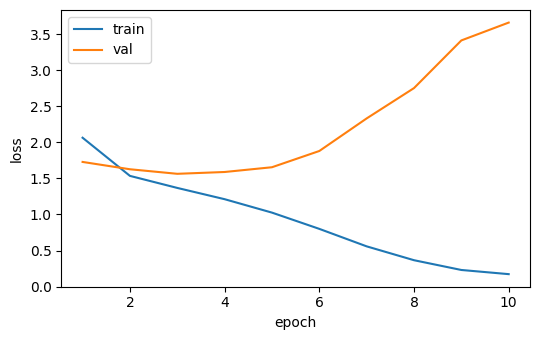

best val loss 1.564 at epoch 3


In [13]:
h = pd.DataFrame(hist)
plt.figure(figsize=(5.5, 3.5)); plt.plot(h.epoch, h.train_loss, label="train"); plt.plot(h.epoch, h.val_loss, label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.tight_layout(); plt.savefig(OUT_DIR / "loss.png", dpi=120); plt.show()
print("best val loss %.3f at epoch %d" % (h.val_loss.min(), h.epoch[h.val_loss.idxmin()]))

## 6. Test evaluation (best checkpoint)

Sentence-BERT cosine uses `all-MiniLM-L6-v2` (use the same model in notebook 5), plus ROUGE-L F1. Rows: constant sentence, model, model with shuffled videos. The `unseen-ID` subset is tiny (see n), so treat it as indicative only.

In [14]:
r = model.load_state_dict(torch.load(BEST, map_location="cpu"), strict=False); assert not r.unexpected_keys
te = IDX["test"]; refs = [meta.text[v] for v in te]
t0 = time.time(); preds = generate(list(te)); print(f"generated {len(te)} in {time.time() - t0:.0f}s")
rng = np.random.RandomState(0)
while True:
    sh = rng.permutation(te)
    if not (sh == te).any(): break
preds_sh = generate(list(sh))

generated 271 in 111s


In [15]:
from sentence_transformers import SentenceTransformer
from rouge_score import rouge_scorer
sb = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cuda")
rs = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
enc = lambda t: sb.encode(t, convert_to_tensor=True, normalize_embeddings=True)

def score(p, r):
    sim = (enc(p) * enc(r)).sum(1).cpu().numpy()
    rl = np.array([rs.score(b, a)["rougeL"].fmeasure for a, b in zip(p, r)])
    return sim, rl

CONST = "The eyes are blurry."
S = {"constant": score([CONST] * len(refs), refs), "model": score(preds, refs), "model (shuffled videos)": score(preds_sh, refs)}
te_meta = meta.iloc[te].reset_index(drop=True)
rows = []
for name, (sim, rl) in S.items():
    for sub, m in [("all", np.ones(len(te), bool)), ("unseen-ID", ~te_meta.id_in_train.values)] + [(k, (te_meta.manipulation == k).values) for k in sorted(te_meta.manipulation.unique())]:
        rows.append({"system": name, "subset": sub, "n": int(m.sum()), "sbert": sim[m].mean(), "rougeL": rl[m].mean()})
res = pd.DataFrame(rows).round(3)
display(res.pivot(index="subset", columns="system", values=["sbert", "rougeL", "n"]).round(3))

d = S["model"][0] - S["model (shuffled videos)"][0]
print("SBERT real - shuffled: mean %.3f, 95%% CI +-%.3f (paired, n=%d)" % (d.mean(), 1.96 * d.std(ddof=1) / np.sqrt(len(d)), len(d)))
d2 = S["model"][0] - S["constant"][0]
print("SBERT model - constant sentence: mean %.3f, 95%% CI +-%.3f" % (d2.mean(), 1.96 * d2.std(ddof=1) / np.sqrt(len(d2))))
vc = pd.Series(preds).value_counts()
print("unique outputs: %d / %d | most common: %s" % (vc.size, len(preds), vc.head(3).to_dict()))
print("mean words: pred %.1f vs reference %.1f" % (np.mean([len(p.split()) for p in preds]), np.mean([len(r_.split()) for r_ in refs])))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

sbert                                  rougeL         \
system      constant  model model (shuffled videos) constant  model   
subset                                                                
Face2Face      0.374  0.560                   0.515    0.153  0.312   
FaceShifter    0.482  0.536                   0.486    0.227  0.282   
FaceSwap       0.456  0.597                   0.543    0.155  0.254   
all            0.437  0.564                   0.515    0.178  0.282   
unseen-ID      0.460  0.539                   0.474    0.194  0.267   

                                           n                                 
system      model (shuffled videos) constant  model model (shuffled videos)  
subset                                                                       
Face2Face                     0.277     90.0   90.0                    90.0  
FaceShifter                   0.262     90.0   90.0                    90.0  
FaceSwap                      0.225     91.0   91.0                    91.0  
all                           0.255    271.0  271.0                   271.0  
unseen-ID                     0.213     15.0   15.0                    15.0

SBERT real - shuffled: mean 0.049, 95% CI +-0.019 (paired, n=271)
SBERT model - constant sentence: mean 0.127, 95% CI +-0.022
unique outputs: 46 / 271 | most common: {'Artifacts on the left side of the face.': 42, 'Artifacts on the right side of the face.': 30, 'Artifacts around the eyes.': 27}
mean words: pred 7.6 vs reference 13.8


In [16]:
out = pd.DataFrame({"key": te_meta.key, "manipulation": te_meta.manipulation, "id_in_train": te_meta.id_in_train, "reference": refs, "pred": preds,
                    "shuffled_from": meta.key.iloc[sh].values, "pred_shuffled": preds_sh, "sbert": S["model"][0], "rougeL": S["model"][1]})
out.to_csv(OUT_DIR / "test_predictions.csv", index=False); res.to_csv(OUT_DIR / "results.csv", index=False)
json.dump({"best_val_loss": best_val, "epochs": len(hist), "n_test": len(te), "train_qformer": TRAIN_QFORMER,
           "sbert_model": "all-MiniLM-L6-v2", "results": res.to_dict("records")}, open(OUT_DIR / "results.json", "w"), indent=1)
for i in np.random.RandomState(1).choice(len(out), 8, replace=False):
    r_ = out.iloc[i]; print(r_.key, f"(sbert {r_.sbert:.2f})", "\n  ref :", r_.reference[:140], "\n  pred:", r_.pred[:140], "\n  shuf:", r_.pred_shuffled[:140], "\n")

FaceSwap/345_259 (sbert 0.69) 
  ref : Strange gaze. Artifacts around the eyes. 
  pred: Artifacts on the right side of the face. 
  shuf: The eyebrows are doubled. 

FaceSwap/949_868 (sbert 0.50) 
  ref : The eyebrows are darting up and down and also get distorted. There is also distortion of the eye which appear to trembling and change shape. 
  pred: Artifacts around the eyes. 
  shuf: Artifacts on the forehead. 

FaceShifter/178_598 (sbert 0.69) 
  ref : The face is blurry with artifacts around the eyes. 
  pred: Artifacts on the right side of the face. 
  shuf: Artifacts on the left side of the face. 

FaceShifter/633_529 (sbert 0.46) 
  ref : Bleed-through eyebrows are wavering. The interior of the mouth is smearing. 
  pred: There are artifacts on the right side of the face. 
  shuf: Artifacts on the right side of the face. 

Face2Face/865_739 (sbert 0.46) 
  ref : There are distortions of the upper teeth. 
  pred: Artifacts on the left side of the face. 
  shuf: Artifacts on th

## Next
- Keep `test_predictions.csv`, `results.csv`, `history.csv` for notebook 5. Save `best.pt` as a dataset only if you want to reuse it (about 0.9 GB); notebook 4 trains its own model with masked inputs.
- Write-up limitations: official split shares source IDs between train and test; Sentence-BERT on short generic sentences rewards style, so read it together with the constant baseline and the shuffled-video control; features are cached, so no image augmentation was used.

In [17]:
import shutil
from IPython.display import FileLink

# 1. Zip the entire /kaggle/working directory
# Note: Do not include '.zip' in the first argument; shutil adds it automatically
shutil.make_archive('notebook3', 'zip', '/kaggle/working/blip2_baseline')

# 2. Generate a clickable download link
FileLink(r'notebook3.zip')

/kaggle/working/notebook3.zip